# Week 4 - Logistic Regression and Feature Scaling

Continuing with the same `ecommerce_data.csv` and feature set from Weeks 2-3 (`Sales`, `Quantity`, `Discount` + one-hot `Segment`, `Region`, `Ship Mode`, `Category`, `Sub-Category`), this week I switch the question from *how much* profit an order makes to a binary one: **is this order profitable at all?** (`Profit > 0`). That's a natural logistic regression target, and it lets this week connect directly to two things already established about this dataset:

- The exact multicollinearity between `Category` and `Sub-Category` diagnosed in Week 2, the reading notes logistic regression is vulnerable to the same multicollinearity problem as linear regression, for the same reason, so it's worth checking whether that shows up here too.
- `Sales` lives on a scale of roughly $0-$14,000 while every dummy variable is 0/1, exactly the scale mismatch the Feature Scaling reading warns distorts both the L1/L2 penalty and gradient-based optimization.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, roc_auc_score, roc_curve,
    confusion_matrix, classification_report,
)

np.random.seed(42)

df = pd.read_csv("ecommerce_data.csv")

numeric_cols = ["Sales", "Quantity", "Discount"]
categorical_cols = ["Segment", "Region", "Ship Mode", "Category", "Sub-Category"]

df_model = df[numeric_cols + categorical_cols + ["Profit"]].copy()
df_X = pd.get_dummies(df_model[numeric_cols + categorical_cols], columns=categorical_cols, drop_first=True).astype(float)
y_binary = (df_model["Profit"] > 0).astype(int).values

print(df_X.shape)
print(f"Profitable orders: {y_binary.mean():.1%}")

(3312, 29)
Profitable orders: 80.7%


About 81% of orders are profitable and 19% are not. This can be considered moderately imbalanced. Accuracy alone can be misleading here (always predicting "profitable" already gets ~81% accuracy), so ROC AUC and a confusion matrix are tracked alongside it throughout.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    df_X, y_binary, test_size=0.25, random_state=42, stratify=y_binary
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

feature_names = df_X.columns.to_numpy()

## 1. Logistic regression on unscaled features - what goes wrong?

Fit logistic regression directly on the raw (unscaled) feature values first, exactly as the reading warns against, to see the actual consequence rather than just taking it on faith.

In [3]:
import warnings
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    unscaled_model = LogisticRegression(max_iter=100, random_state=42)
    unscaled_model.fit(X_train, y_train)
    for w in caught:
        print(f"{w.category.__name__}: {w.message}")

unscaled_coefs = pd.Series(unscaled_model.coef_[0], index=feature_names)
print()
print("Largest unscaled coefficients by magnitude:")
print(unscaled_coefs.abs().sort_values(ascending=False).head(8))

STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression

Largest unscaled coefficients by magnitude:
Discount                    9.244627
Sub-Category_Paper          2.779439
Sub-Category_Storage        2.615751
Category_Office Supplies    2.446829
Sub-Category_Tables         2.056892
Sub-Category_Art            2.004377
Region_West                 1.477587
Sub-Category_Binders        1.247663
dtype: float64


In [4]:
scaled_model = LogisticRegression(max_iter=100, random_state=42)
scaled_model.fit(X_train_scaled, y_train)

scaled_coefs = pd.Series(scaled_model.coef_[0], index=feature_names)
print("Largest scaled coefficients by magnitude:")
print(scaled_coefs.abs().sort_values(ascending=False).head(8))

Largest scaled coefficients by magnitude:
Discount                    4.482227
Sub-Category_Storage        1.107800
Category_Office Supplies    0.920271
Sub-Category_Paper          0.804115
Sub-Category_Art            0.681519
Sub-Category_Copiers        0.599465
Sub-Category_Binders        0.475499
Category_Technology         0.475395
dtype: float64


The unscaled fit threw a `ConvergenceWarning` within the same 100-iteration budget that the scaled model converged in cleanly, `lbfgs` couldn't find a stable solution on the raw feature scales. That's the direct, practical version of the reading's gradient-descent warning: the optimizer struggles when features span wildly different ranges (`Sales` in the thousands vs. 0/1 dummies), even though the final top-8 coefficient lists look fairly similar between the two models. The *rankings* aren't quite stable either, `Region_West` and `Sub-Category_Tables` place in the unscaled top 8 but drop out once scaled, while `Category_Technology` and `Sub-Category_Copiers` only appear once scaling puts every feature on the same footing. Raw coefficient size is scale-dependent (a feature with naturally large values needs a smaller coefficient to have the same effect), so comparing unscaled coefficients across features of different scales is misleading, which is why every model from here on uses the scaled features.

## 2. Cross-validated logistic regression (L2) on scaled features

Use `LogisticRegressionCV` to search over regularization strength automatically (same idea as `RidgeCV`/`LassoCV` from Week 2, just for a classification loss cross-entropy instead of squared error).

In [5]:
l2_model = LogisticRegressionCV(
    Cs=np.logspace(-2, 3, 50),
    penalty="l2",
    cv=5,
    scoring="roc_auc",
    max_iter=5000,
    random_state=42,
).fit(X_train_scaled, y_train)

print(f"Selected C (inverse regularization strength): {l2_model.C_[0]:.3f}")

l2_preds = l2_model.predict(X_test_scaled)
l2_proba = l2_model.predict_proba(X_test_scaled)[:, 1]

print(f"Test accuracy: {accuracy_score(y_test, l2_preds):.3f}")
print(f"Test ROC AUC: {roc_auc_score(y_test, l2_proba):.3f}")
print()
print(confusion_matrix(y_test, l2_preds))
print()
print(classification_report(y_test, l2_preds, target_names=["Not profitable", "Profitable"]))

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1780: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1811: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratios' instead. Use l1_ratios=(0,) instead of penalty='l2'  and l1_ratios=(1,) instead of penalty='l1'.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1823: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or 

Selected C (inverse regularization strength): 59.636
Test accuracy: 0.925
Test ROC AUC: 0.976

[[127  33]
 [ 29 639]]

                precision    recall  f1-score   support

Not profitable       0.81      0.79      0.80       160
    Profitable       0.95      0.96      0.95       668

      accuracy                           0.93       828
     macro avg       0.88      0.88      0.88       828
  weighted avg       0.92      0.93      0.92       828



## 3. L1-penalized logistic regression - does feature selection help here?

The same L1 idea from Week 2's Lasso, applied to the classification loss this time, to see whether it prunes any of the 29 features the way Lasso pruned a couple of weak predictors from the continuous Profit model. `liblinear` is used here since it supports the L1 penalty directly for binary classification.

In [6]:
l1_model = LogisticRegressionCV(
    Cs=np.logspace(-2, 3, 50),
    penalty="l1",
    solver="liblinear",
    cv=5,
    scoring="roc_auc",
    max_iter=5000,
    random_state=42,
).fit(X_train_scaled, y_train)

print(f"Selected C: {l1_model.C_[0]:.3f}")

l1_coefs = pd.Series(l1_model.coef_[0], index=feature_names)
n_nonzero = int((l1_coefs.abs() > 1e-6).sum())
print(f"Nonzero coefficients: {n_nonzero} of {len(feature_names)}")
print()
print("Dropped to exactly zero:")
print(list(l1_coefs[l1_coefs.abs() <= 1e-6].index))

l1_preds = l1_model.predict(X_test_scaled)
l1_proba = l1_model.predict_proba(X_test_scaled)[:, 1]
print()
print(f"Test accuracy: {accuracy_score(y_test, l1_preds):.3f}")
print(f"Test ROC AUC: {roc_auc_score(y_test, l1_proba):.3f}")

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1780: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1811: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratios' instead. Use l1_ratios=(0,) instead of penalty='l2'  and l1_ratios=(1,) instead of penalty='l1'.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1823: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or 

Selected C: 193.070
Nonzero coefficients: 29 of 29

Dropped to exactly zero:
[]

Test accuracy: 0.926
Test ROC AUC: 0.976


## 4. ROC curves

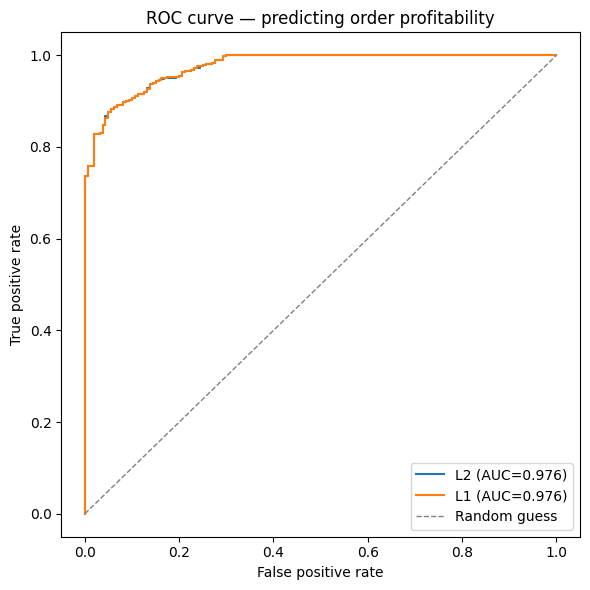

In [7]:
fpr_l2, tpr_l2, _ = roc_curve(y_test, l2_proba)
fpr_l1, tpr_l1, _ = roc_curve(y_test, l1_proba)

plt.figure(figsize=(6, 6))
plt.plot(fpr_l2, tpr_l2, label=f"L2 (AUC={roc_auc_score(y_test, l2_proba):.3f})")
plt.plot(fpr_l1, tpr_l1, label=f"L1 (AUC={roc_auc_score(y_test, l1_proba):.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray", linewidth=1, label="Random guess")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curve — predicting order profitability")
plt.legend()
plt.tight_layout()
plt.show()

## 5. Interpreting coefficients as odds ratios

For logistic regression, $e^{\beta_i}$ is the multiplicative change in the odds of the outcome (profitable vs. not) for a 1-standard-deviation increase in that (scaled) feature, holding the others fixed.

In [8]:
odds_ratios = np.exp(pd.Series(l2_model.coef_[0], index=feature_names))
odds_table = pd.DataFrame({
    "coefficient": l2_model.coef_[0],
    "odds_ratio": odds_ratios,
}, index=feature_names).sort_values("coefficient")

print(odds_table.round(3))

                          coefficient  odds_ratio
Discount                       -5.116       0.006
Sub-Category_Storage           -1.385       0.250
Category_Technology            -0.644       0.525
Sub-Category_Chairs            -0.547       0.579
Sub-Category_Tables            -0.511       0.600
Sub-Category_Supplies          -0.508       0.602
Sub-Category_Bookcases         -0.394       0.675
Sub-Category_Fasteners         -0.372       0.689
Ship Mode_Standard Class       -0.257       0.773
Sales                          -0.242       0.785
Sub-Category_Furnishings       -0.202       0.817
Ship Mode_Second Class         -0.177       0.837
Segment_Home Office            -0.066       0.936
Ship Mode_Same Day              0.044       1.045
Segment_Corporate               0.067       1.069
Region_South                    0.135       1.145
Region_West                     0.199       1.220
Region_East                     0.289       1.335
Quantity                        0.334       1.397


## 6. Conclusions

- **Scaling mattered for optimization, not just interpretation.** The unscaled logistic regression hit a `ConvergenceWarning`, and even its coefficient *rankings* differed from the scaled version's. This is the feature-scaling reading's gradient-descent warning showing up directly, not just a theoretical concern.
- **Order profitability is far easier to predict than exact profit dollars.** This week's classifier reached test ROC AUC = 0.976 and 92.5% accuracy, while Weeks 2–3's continuous Profit regressions topped out around R² ≈ 0.28–0.29 on the same features. That gap is itself a finding: whether an order loses money is close to deterministic given discount/category/region, but the *exact size* of the profit or loss depends on factors not in this feature set (shipping cost, returns, negotiated pricing).
- **Discount is overwhelmingly the dominant predictor.** Its odds ratio of ≈0.006 means a 1-standard-deviation increase in discount rate multiplies the odds of an order being profitable by roughly 1/166, heavily discounted orders are almost never profitable in this data. No other feature comes close in magnitude, which matches Discount also being the most stable, largest-magnitude coefficient back in Week 2's dollar-profit model.
- **L1 regularization chose not to prune anything.** Cross-validation selected a very weak penalty (C ~ 193) and kept all 29 coefficients nonzero, unlike Week 2's Lasso, which did zero out `Sub-Category_Art` and shrink `Category_Office Supplies` toward zero for the continuous target. For this classification task, apparently, the class separation is clean enough (ROC AUC 0.976) that CV found no generalization benefit to dropping features. The `Category`/`Sub-Category` multicollinearity the reading warns is also a problem for logistic regression. It didn't end up costing this model anything, likely because predicting the binary outcome is simply a less demanding task for these features than predicting the exact dollar amount was.
- **Direction of effects is broadly consistent with Weeks 2–3, with one notable addition.** `Sub-Category_Tables` and `Sub-Category_Chairs` are again associated with lower profitability, echoing their negative dollar-profit coefficients from Week 2. But `Category_Technology` also shows up as a mild negative predictor of simply *being* profitable here, a pattern not flagged by the earlier dollar-amount models, suggesting Technology orders may follow more of a "big win or loss" pattern (a few highly profitable orders pulling up the average dollar coefficient while a large share of individual orders still land on the loss side).